# Stage 1B: Transformer versus semantic-parameter codebook

This notebook sends the four configured test images through a sequential knowledge base, renders the requested image/parameter/header/payload figure, then compares the Transformer and Swin-codebook semantic paths. The existing Stage 1A VQ packet remains separate from the semantic header.

## 1. Setup and explicit experiment inputs

In [1]:
from __future__ import annotations

import json
import os
import platform
import subprocess
import sys
from pathlib import Path


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'src').is_dir():
            return candidate
    raise RuntimeError('Run this notebook from the SemanticSchedulerEnd2End repository or a child directory.')


PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
SOURCE_ROOT = PROJECT_ROOT / 'src'
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))


def git_commit() -> str:
    try:
        return subprocess.check_output(['git', '-C', str(PROJECT_ROOT), 'rev-parse', 'HEAD'], text=True).strip()
    except Exception:
        return 'unavailable'


RUN_CONTEXT = {
    'project_root': str(PROJECT_ROOT),
    'git_commit': git_commit(),
    'python': platform.python_version(),
}
print(json.dumps(RUN_CONTEXT, indent=2))


{
  "project_root": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End",
  "git_commit": "6736d926cfe6de9b5c162b93a8b12758ba026634",
  "python": "3.12.14"
}


In [2]:
from utils.config_loader import load_yaml_config
from TransformerPipeline.benchmark import artifact_size_bytes, benchmark_callable
from TransformerPipeline.runtime import run_semantic_demo

STAGE1B_CONFIG_PATH = PROJECT_ROOT / 'config' / 'stage1b.yaml'
STAGE1C_CONFIG_PATH = PROJECT_ROOT / 'config' / 'stage1c_parameter_codebook.yaml'
stage1b_config = load_yaml_config(STAGE1B_CONFIG_PATH)
stage1c_config = load_yaml_config(STAGE1C_CONFIG_PATH)
MODEL_DIR = PROJECT_ROOT / 'models' / 'SwinJSCC'
COMMUNICATION_VQ_PATH = PROJECT_ROOT / 'models' / 'Codebooks' / 'swinjscc_tx_k256.joblib'
PARAMETER_CODEBOOK_PATH = PROJECT_ROOT / stage1c_config['parameter_codebook']['artifact_path']
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'stage1b_semantic_showcase'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_DIR.is_dir():
    raise FileNotFoundError(f'Missing manifest-validated Stage 1A model directory: {MODEL_DIR}')
if not PARAMETER_CODEBOOK_PATH.is_file():
    raise FileNotFoundError(
        f'Missing semantic parameter codebook: {PARAMETER_CODEBOOK_PATH}. Run the local training notebook first.'
    )
VQ_ARGUMENT = COMMUNICATION_VQ_PATH if COMMUNICATION_VQ_PATH.is_file() else None
if VQ_ARGUMENT is None:
    print('Communication VQ artifact is absent: the figure will show VQ payload as unavailable, not fabricate one.')

RUN_CONTEXT.update(
    {
        'stage1b_config': str(STAGE1B_CONFIG_PATH),
        'stage1c_config': str(STAGE1C_CONFIG_PATH),
        'model_dir': str(MODEL_DIR),
        'parameter_codebook': str(PARAMETER_CODEBOOK_PATH),
        'communication_vq': str(VQ_ARGUMENT) if VQ_ARGUMENT else None,
    }
)
print(json.dumps(RUN_CONTEXT, indent=2))


{
  "project_root": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End",
  "git_commit": "6736d926cfe6de9b5c162b93a8b12758ba026634",
  "python": "3.12.14",
  "stage1b_config": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End\\config\\stage1b.yaml",
  "stage1c_config": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End\\config\\stage1c_parameter_codebook.yaml",
  "model_dir": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End\\models\\SwinJSCC",
  "parameter_codebook": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End\\models\\SemanticCodebooks\\emergency_building_fire_demo.npz",
  "communication_vq": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End\\models\\Codebooks\\swinjscc_tx_k256.joblib"
}


## 2. Transformer path: sequential knowledge base, semantic sidecar, and showcase figure

D:\Bunker\BaseCamp\WirelessCommunication\SemanticComms\SemanticSchedulerEnd2End\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


D:\Bunker\BaseCamp\WirelessCommunication\SemanticComms\SemanticSchedulerEnd2End\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
D:\Bunker\BaseCamp\WirelessCommunication\SemanticComms\SemanticSchedulerEnd2End\.venv\Lib\site-packages\torch\functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4383.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Encoder  dim=3, input_resolution=(1024, 1024), depth=2
Encoder  dim=128, input_resolution=(512, 512), depth=2
Encoder  dim=192, input_resolution=(256, 256), depth=6
Encoder  dim=256, input_resolution=(128, 128), depth=2


Decoder  dim=320, input_resolution=(64, 64), depth=2
Decoder  dim=256, input_resolution=(128, 128), depth=6
Decoder  dim=192, input_resolution=(256, 256), depth=2


Decoder  dim=128, input_resolution=(512, 512), depth=2


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


... (2 outputs left out)

SEMANTIC HEADER
  bytes=42 bits=336
  AoI_seconds: 55.000000 seconds [ue]
  freshness: 0.004089 normalized_score [ue]
  novelty: 0.488930 normalized_score [ue]
  relevance: 0.599176 normalized_score [ue]
  reliability: 0.173159 normalized_score [ue]
  urgency: 0.000000 normalized_score [ue]
  task_importance: 0.646784 normalized_score [ue]
  hex_preview=53485001070101040000d6d8020102010c0301027d2a04010299630501022c540601020000070102a593
NATIVE LATENT PAYLOAD
  shape=(1, 4096, 320) active_real_values=393216
  preview=[0, -0, -0.1629, -0, -0, 0, 0.9731, -0.08109]
COMMUNICATION VQ PAYLOAD
  codebook_id=swinjscc_tx_k256 payload_bits_per_image=[33248]
  index_preview=[206, 206, 195, 195, 206, 206, 195, 195]
  note=communication VQ framing remains separate from the semantic header


SEMANTIC HEADER
  bytes=40 bits=320
  AoI_seconds: 120.000000 seconds [ue]
  freshness: 0.000000 normalized_score [ue]
  novelty: 0.483024 normalized_score [ue]
  relevance: 0.590356 normalized_score [ue]
  reliability: 0.220493 normalized_score [ue]
  urgency: unavailable [ue]
  task_importance: 0.588968 normalized_score [ue]
  hex_preview=53485001070101040001d4c002010200000301027ba70401029721050102387206000007010296c6
NATIVE LATENT PAYLOAD
  shape=(1, 64, 320) active_real_values=6144
  preview=[0, -0, -0.8628, 0, 0, -0, -1.57, 0.7147]
COMMUNICATION VQ PAYLOAD
  codebook_id=swinjscc_tx_k256 payload_bits_per_image=[992]
  index_preview=[122, 35, 210, 210, 122, 35, 194, 41]
  note=communication VQ framing remains separate from the semantic header


{
  "status": "semantic_demo_complete",
  "param_extractor": "transformer",
  "image_count": 4,
  "knowledge_observation_count": 4,
  "semantic_header_bytes": [
    42,
    42,
    42,
    40
  ],
  "output_plot": "D:\\Bunker\\BaseCamp\\WirelessCommunication\\SemanticComms\\SemanticSchedulerEnd2End\\results\\stage1b_semantic_showcase\\transformer_semantic_header_showcase.png",
  "note": "semantic header is a logical sidecar and is not included in Stage 1A VQ packet accounting"
}
Rendered figure: D:\Bunker\BaseCamp\WirelessCommunication\SemanticComms\SemanticSchedulerEnd2End\results\stage1b_semantic_showcase\transformer_semantic_header_showcase.png


D:\Bunker\BaseCamp\WirelessCommunication\SemanticComms\SemanticSchedulerEnd2End\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


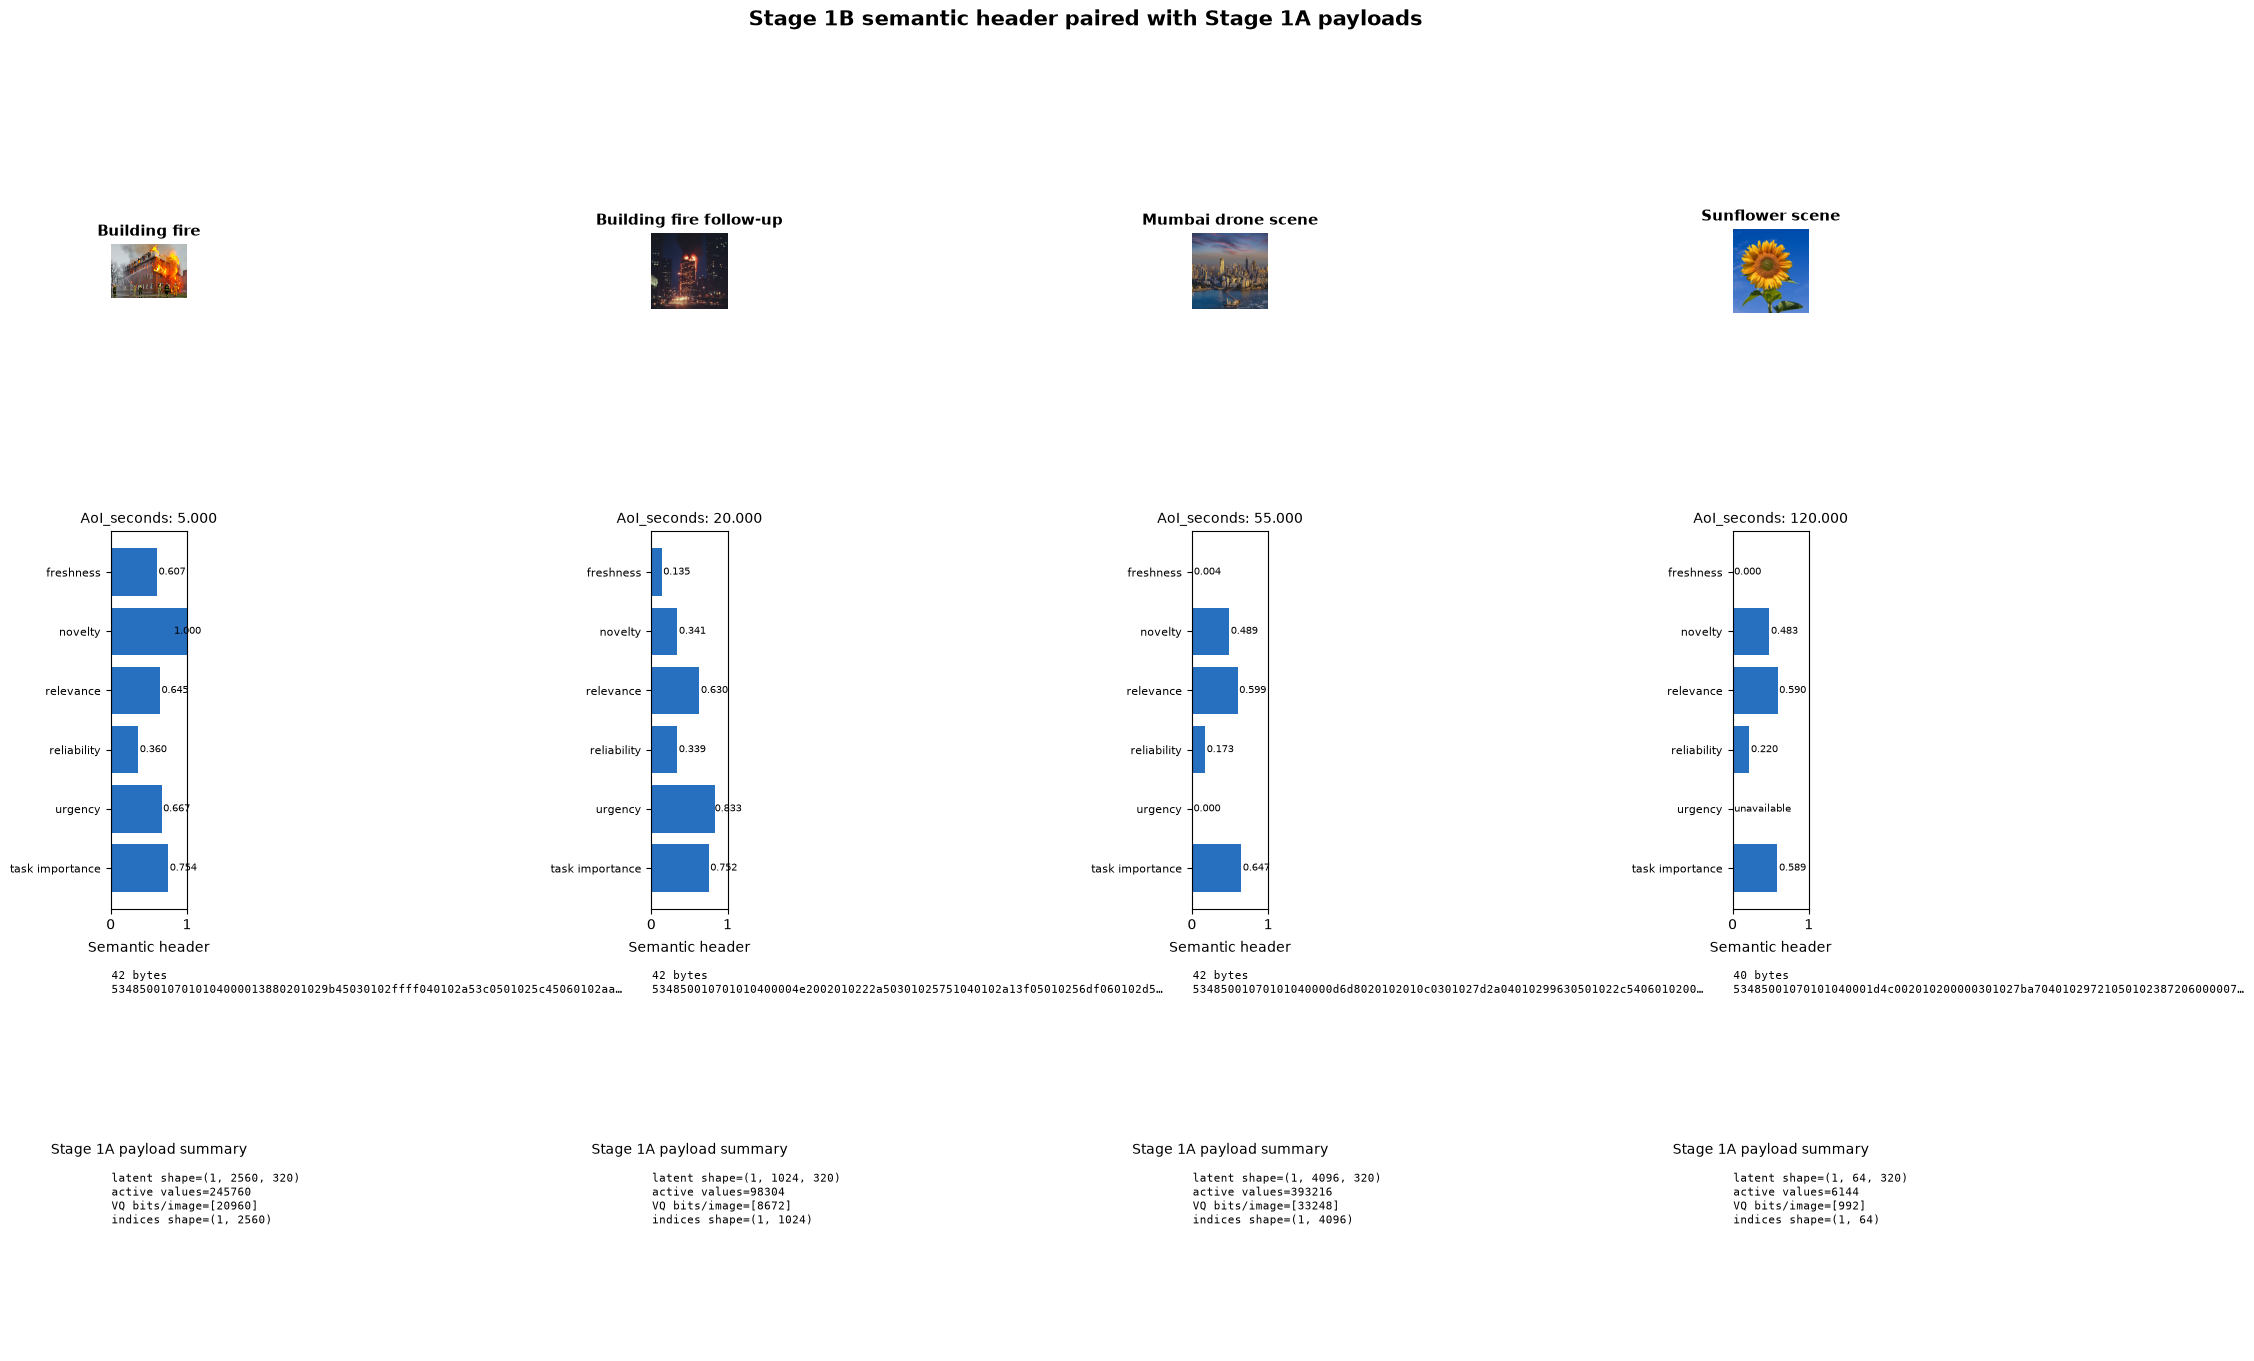

In [3]:
TRANSFORMER_FIGURE = OUTPUT_DIR / 'transformer_semantic_header_showcase.png'
transformer_result = run_semantic_demo(
    stage1b_config,
    param_extractor='transformer',
    model_dir=MODEL_DIR,
    communication_codebook_path=VQ_ARGUMENT,
    device='auto',
    output_plot=TRANSFORMER_FIGURE,
)
print(json.dumps({key: value for key, value in transformer_result.items() if key != 'parameter_bundles'}, indent=2))
print('Rendered figure:', TRANSFORMER_FIGURE)


## 3. Semantic parameter-codebook path

In [4]:
codebook_result = run_semantic_demo(
    stage1b_config,
    param_extractor='codebook',
    model_dir=MODEL_DIR,
    communication_codebook_path=VQ_ARGUMENT,
    semantic_codebook_path=PARAMETER_CODEBOOK_PATH,
    device='auto',
)
print(json.dumps({key: value for key, value in codebook_result.items() if key != 'parameter_bundles'}, indent=2))


Encoder  dim=3, input_resolution=(1024, 1024), depth=2
Encoder  dim=128, input_resolution=(512, 512), depth=2
Encoder  dim=192, input_resolution=(256, 256), depth=6
Encoder  dim=256, input_resolution=(128, 128), depth=2


Decoder  dim=320, input_resolution=(64, 64), depth=2
Decoder  dim=256, input_resolution=(128, 128), depth=6
Decoder  dim=192, input_resolution=(256, 256), depth=2


Decoder  dim=128, input_resolution=(512, 512), depth=2


SEMANTIC HEADER
  bytes=42 bits=336
  AoI_seconds: 5.000000 seconds [ue]
  freshness: 0.606531 normalized_score [ue]
  novelty: 1.000000 normalized_score [ue]
  relevance: 0.592737 normalized_score [ue]
  reliability: 0.170184 normalized_score [ue]
  urgency: 0.666667 normalized_score [ue]
  task_importance: 0.621225 normalized_score [ue]
  hex_preview=5348500107010104000013880201029b45030102ffff04010297bd0501022b91060102aaaa0701029f08
NATIVE LATENT PAYLOAD
  shape=(1, 2560, 320) active_real_values=245760
  preview=[-0, 0, 0.005339, 0, 0, -0, -0.1047, -0.6481]
COMMUNICATION VQ PAYLOAD
  codebook_id=swinjscc_tx_k256 payload_bits_per_image=[20960]
  index_preview=[115, 115, 115, 115, 115, 115, 115, 115]
  note=communication VQ framing remains separate from the semantic header


SEMANTIC HEADER
  bytes=42 bits=336
  AoI_seconds: 20.000000 seconds [ue]
  freshness: 0.135332 normalized_score [ue]
  novelty: 1.000000 normalized_score [ue]
  relevance: 0.590051 normalized_score [ue]
  reliability: 0.163531 normalized_score [ue]
  urgency: 0.833326 normalized_score [ue]
  task_importance: 0.623636 normalized_score [ue]
  hex_preview=534850010701010400004e2002010222a5030102ffff040102970d05010229dd060102d5540701029fa6
NATIVE LATENT PAYLOAD
  shape=(1, 1024, 320) active_real_values=98304
  preview=[0, -0, -0.1013, -0, -0, 0, -0.2847, 0.4533]
COMMUNICATION VQ PAYLOAD
  codebook_id=swinjscc_tx_k256 payload_bits_per_image=[8672]
  index_preview=[114, 114, 114, 114, 157, 157, 157, 157]
  note=communication VQ framing remains separate from the semantic header


SEMANTIC HEADER
  bytes=42 bits=336
  AoI_seconds: 55.000000 seconds [ue]
  freshness: 0.004089 normalized_score [ue]
  novelty: 0.389197 normalized_score [ue]
  relevance: 0.592737 normalized_score [ue]
  reliability: 0.170184 normalized_score [ue]
  urgency: 0.000000 normalized_score [ue]
  task_importance: 0.621225 normalized_score [ue]
  hex_preview=53485001070101040000d6d8020102010c03010263a204010297bd0501022b9106010200000701029f08
NATIVE LATENT PAYLOAD
  shape=(1, 4096, 320) active_real_values=393216
  preview=[0, -0, -0.1629, -0, -0, 0, 0.9731, -0.08109]
COMMUNICATION VQ PAYLOAD
  codebook_id=swinjscc_tx_k256 payload_bits_per_image=[33248]
  index_preview=[206, 206, 195, 195, 206, 206, 195, 195]
  note=communication VQ framing remains separate from the semantic header


SEMANTIC HEADER
  bytes=40 bits=320
  AoI_seconds: 120.000000 seconds [ue]
  freshness: 0.000000 normalized_score [ue]
  novelty: 0.278599 normalized_score [ue]
  relevance: 0.590051 normalized_score [ue]
  reliability: 0.163531 normalized_score [ue]
  urgency: unavailable [ue]
  task_importance: 0.623636 normalized_score [ue]
  hex_preview=53485001070101040001d4c002010200000301024752040102970d05010229dd0600000701029fa6
NATIVE LATENT PAYLOAD
  shape=(1, 64, 320) active_real_values=6144
  preview=[0, -0, -0.8628, 0, 0, -0, -1.57, 0.7147]
COMMUNICATION VQ PAYLOAD
  codebook_id=swinjscc_tx_k256 payload_bits_per_image=[992]
  index_preview=[122, 35, 210, 210, 122, 35, 194, 41]
  note=communication VQ framing remains separate from the semantic header
{
  "status": "semantic_demo_complete",
  "param_extractor": "codebook",
  "image_count": 4,
  "knowledge_observation_count": 4,
  "semantic_header_bytes": [
    42,
    42,
    42,
    40
  ],
  "output_plot": null,
  "note": "semantic header 

## 4. Parameter differences and semantic-header overhead

In [5]:
import pandas as pd

rows = []
for image_entry, transformer_bundle, codebook_bundle in zip(
    stage1b_config['demo']['images'],
    transformer_result['parameter_bundles'],
    codebook_result['parameter_bundles'],
    strict=True,
):
    for parameter_name, transformer_value in transformer_bundle['values'].items():
        codebook_value = codebook_bundle['values'][parameter_name]
        transformer_score = transformer_value['value']
        codebook_score = codebook_value['value']
        rows.append(
            {
                'image': image_entry['filename'],
                'parameter': parameter_name,
                'transformer_value': transformer_score,
                'codebook_value': codebook_score,
                'absolute_difference': None
                if transformer_score is None or codebook_score is None
                else abs(transformer_score - codebook_score),
                'transformer_available': transformer_value['available'],
                'codebook_available': codebook_value['available'],
            }
        )
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv(OUTPUT_DIR / 'parameter_comparison.csv', index=False)
print(
    {
        'transformer_header_bytes': transformer_result['semantic_header_bytes'],
        'codebook_header_bytes': codebook_result['semantic_header_bytes'],
        'parameter_codebook_bytes': artifact_size_bytes(PARAMETER_CODEBOOK_PATH),
        'communication_vq_bytes': artifact_size_bytes(VQ_ARGUMENT) if VQ_ARGUMENT else None,
    }
)


,image,parameter,transformer_value,codebook_value,absolute_difference,transformer_available,codebook_available
0,BuildingFire.jpeg,AoI_seconds,5.000000,5.000000,0.000000,True,True
1,BuildingFire.jpeg,freshness,0.606531,0.606531,0.000000,True,True
2,BuildingFire.jpeg,novelty,1.000000,1.000000,0.000000,True,True
3,BuildingFire.jpeg,relevance,0.645462,0.592731,0.052731,True,True
4,BuildingFire.jpeg,reliability,0.360437,0.170183,0.190254,True,True
5,BuildingFire.jpeg,urgency,0.666667,0.666667,0.000000,True,True
6,BuildingFire.jpeg,task_importance,0.753903,0.621218,0.132685,True,True
7,BuildingFire2.jpeg,AoI_seconds,20.000000,20.000000,0.000000,True,True
8,BuildingFire2.jpeg,freshness,0.135335,0.135335,0.000000,True,True
9,BuildingFire2.jpeg,novelty,0.341089,1.000000,0.658911,True,True


{'transformer_header_bytes': [42, 42, 42, 40], 'codebook_header_bytes': [42, 42, 42, 40], 'parameter_codebook_bytes': 16642, 'communication_vq_bytes': 329592}

## 5. Full-series latency and memory comparison

In [6]:
import contextlib
import io


def quiet_run(extractor_name: str):
    with contextlib.redirect_stdout(io.StringIO()):
        return run_semantic_demo(
            stage1b_config,
            param_extractor=extractor_name,
            model_dir=MODEL_DIR,
            communication_codebook_path=VQ_ARGUMENT,
            semantic_codebook_path=PARAMETER_CODEBOOK_PATH if extractor_name == 'codebook' else None,
            device='auto',
        )


# These are environment-specific, end-to-end image-series measurements. They
# include model/artifact loading and must not be presented as radio latency.
benchmark_rows = [
    {'path': 'transformer', **benchmark_callable(lambda: quiet_run('transformer'), warmup_runs=1, measured_runs=3)},
    {'path': 'codebook', **benchmark_callable(lambda: quiet_run('codebook'), warmup_runs=1, measured_runs=3)},
]
benchmark = pd.DataFrame(benchmark_rows)
display(benchmark)
benchmark.to_csv(OUTPUT_DIR / 'latency_memory_comparison.csv', index=False)


,path,cold_latency_ms,warm_latency_median_ms,warm_latency_p95_ms,measured_runs,cpu_rss_before_bytes,cpu_rss_after_bytes
0,transformer,130647.9342,198765.7443,202663.5178,3,4246855680,44523520
1,codebook,80244.2309,20726.4248,22263.4175,3,44662784,4094906368


## 6. Validation limits

Inspect the saved PNG at reading size after execution. The codebook is a local 24-image Kodak engineering prototype only. Its comparison reports latency, memory, header size, and parameter differences; it does not establish accuracy, generalization, scheduler behavior, or physical-layer header overhead.